In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

In [19]:
train_db = pd.read_csv('application_train.csv')
test_db = pd.read_csv('application_test.csv')

print(f'Розмір тестувального датасету: {train_db.shape}')
print(f'Розмір валідаційного датасету: {test_db.shape}')

y = train_db['TARGET']
x = train_db.drop(columns = ['TARGET', 'SK_ID_CURR'])

test_ids = test_db['SK_ID_CURR']
X_test_submition = test_db.drop(columns = ['SK_ID_CURR'])

print(f'РОзмір х: {x.shape}')
print(f'РОзмір y: {y.shape}')

Розмір тестувального датасету: (307511, 122)
Розмір валідаційного датасету: (48744, 121)
РОзмір х: (307511, 120)
РОзмір y: (307511,)


In [20]:
numeric_columns = x.select_dtypes(include=['int64', 'float64']).columns
categorical_columns = x.select_dtypes(include=['object']).columns

for col in numeric_columns:
    median_val = x[col].median()
    x[col].fillna(median_val, inplace=True)
    X_test_submition[col].fillna(median_val, inplace=True)

for col in categorical_columns:
    x[col].fillna('Unknown', inplace=True)
    X_test_submition[col].fillna('Unknown', inplace=True)

x_encoded = pd.get_dummies(x, columns=categorical_columns)
x_test_encoded = pd.get_dummies(X_test_submition, columns=categorical_columns)

x_encoded, x_test_encoded = x_encoded.align(x_test_encoded, join='inner', axis=1)

print(f"Розмір X після обробки: {x_encoded.shape}")
print(f"Розмір X_test після обробки: {x_test_encoded.shape}")

Розмір X після обробки: (307511, 241)
Розмір X_test після обробки: (48744, 241)


In [21]:
print("Розділення на навчальну та валідаційну вибірки")

X_train, X_val, y_train, y_val = train_test_split(
    x_encoded, 
    y, 
    test_size=0.2, 
    random_state=42
)

print(f"Розмір навчальної вибірки (X_train): {X_train.shape}")
print(f"Розмір валідаційної вибірки (X_val): {X_val.shape}")

Розділення на навчальну та валідаційну вибірки
Розмір навчальної вибірки (X_train): (246008, 241)
Розмір валідаційної вибірки (X_val): (61503, 241)


ROC-AUC на валідаційній вибірці: 0.5384
Матриця помилок


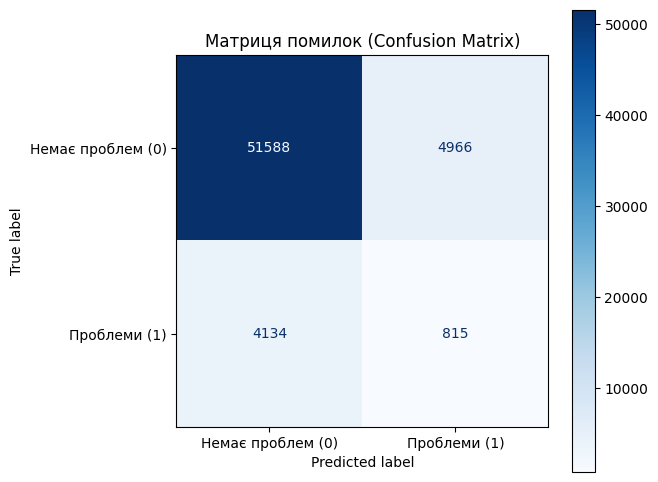

In [22]:
clf = DecisionTreeClassifier(random_state=42)

clf.fit(X_train, y_train)

y_val_pred_proba = clf.predict_proba(X_val)[:, 1]

roc_auc = roc_auc_score(y_val, y_val_pred_proba)
print(f"ROC-AUC на валідаційній вибірці: {roc_auc:.4f}")

y_val_pred = clf.predict(X_val)

print("Матриця помилок")
cm = confusion_matrix(y_val, y_val_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Немає проблем (0)', 'Проблеми (1)'])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Матриця помилок (Confusion Matrix)")
plt.show()

In [26]:
test_predictions = clf.predict_proba(x_test_encoded)[:, 1]

submission_df = pd.DataFrame({
    'SK_ID_CURR': test_ids,
    'TARGET': test_predictions
})

submission_filename = 'submission.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"Файл {submission_filename} збережено")

Файл submission.csv збережено


![Знімок екрана 2026-10-08 о 17.35.48.png](<attachment:Знімок екрана 2026-10-08 о 17.35.48.png>)


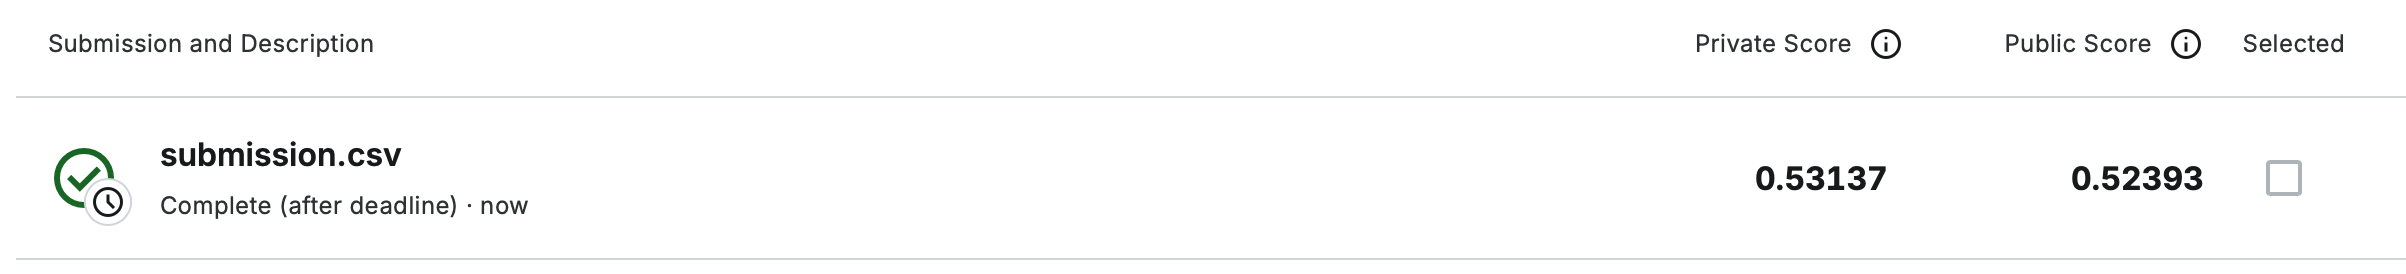